EJERCICIO F1: ASIGNACIÓN DE TIEMPO EN TÚNEL DE VIENTO - SIMPLEX GENERAL

--- PASO 1: MODELO MATEMÁTICO ---
Variables de decisión:
  x1 = paquetes aerodinámicos desarrollados
  x2 = paquetes de motor desarrollados

Función objetivo:
  max z = 40*x1 + 30*x2

Restricciones:
  2*x1 + 1*x2 <= 8   (Túnel de viento)
  2*x1 + 3*x2 <= 12  (Banco de pruebas)
  1*x1 + 1*x2 <= 5   (Tokens de desarrollo)
  x1, x2 >= 0

--- PASO 2: FORMA ESTÁNDAR ---
Se agregan holguras s1, s2, s3 >= 0:
  2*x1 + 1*x2 + s1 = 8
  2*x1 + 3*x2 + s2 = 12
  1*x1 + 1*x2 + s3 = 5
  z - 40*x1 - 30*x2 = 0

Base inicial: {s1, s2, s3} -> solución (0,0,0)

--- PASO 3: TABLA SIMPLEX PASO A PASO ---

Iteración 0 (inicial)
Base          x1      x2      s1      s2      s3     Sol
--------------------------------------------------------
s1          2.00    1.00    1.00    0.00    0.00    8.00
s2          2.00    3.00    0.00    1.00    0.00   12.00
s3          1.00    1.00    0.00    0.00    1.00    5.00
z         -40.00  -30.00    0

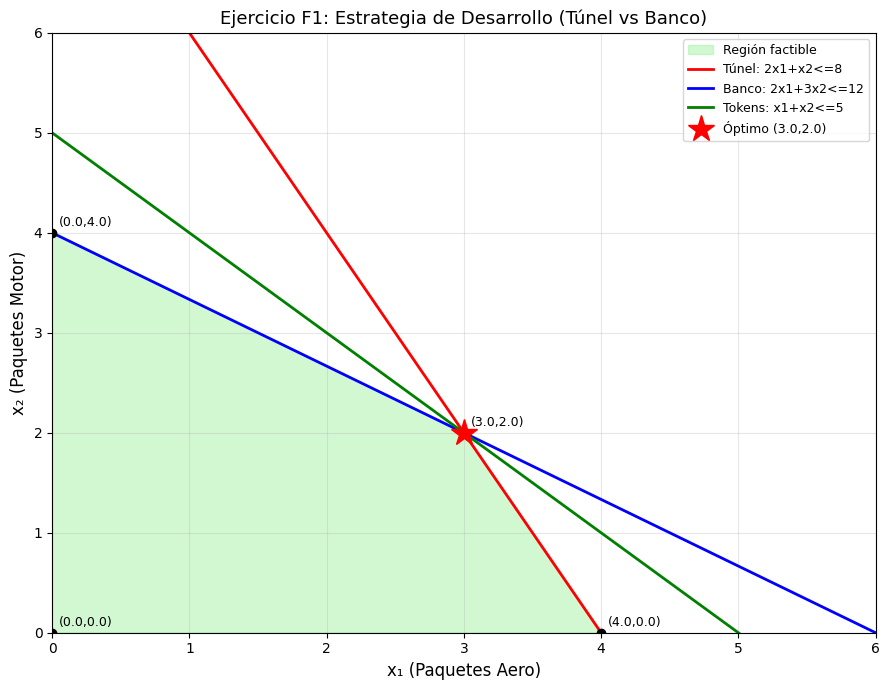


--- PASO 7: ANÁLISIS DE SENSIBILIDAD ---
Precios sombra:
  y_s1 (Túnel)      = 15.00 milésimas por unidad extra
  y_s2 (Banco)      = 5.00 milésimas por unidad extra
  y_s3 (Tokens)     = 0.00 milésimas por unidad extra

Holguras en el óptimo:
  s1 = 0.00
  s2 = 0.00
  s3 = 0.00

--- PASO 8: CONCLUSIÓN ESTRATÉGICA ---
1. La estrategia óptima es desarrollar 3 paquetes aero y 2 de motor.
2. Se ganan 180 milésimas por vuelta.
3. Las horas de túnel y banco de pruebas se agotan por completo.
4. Queda 1 token de desarrollo sin usar (holgura).


In [ ]:
# =====================================================================
# EJERCICIO F1: ASIGNACIÓN DE TIEMPO EN TÚNEL DE VIENTO - SIMPLEX GENERAL
# =====================================================================
# PROBLEMA:
#   Un equipo de F1 optimiza su tiempo de desarrollo en túnel y banco.
#   Ganancia: 40 milésimas por paquete aero (x1), 30 por motor (x2).
#   Restricciones:
#     2x1 + 1x2 <= 8   (Horas de túnel de viento)
#     2x1 + 3x2 <= 12  (Horas de banco de pruebas)
#     1x1 + 1x2 <= 5   (Tokens de desarrollo)
#
# OBJETIVO: maximizar el tiempo ganado por vuelta (milésimas).
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from itertools import combinations

print("="*70)
print("EJERCICIO F1: ASIGNACIÓN DE TIEMPO EN TÚNEL DE VIENTO - SIMPLEX GENERAL")
print("="*70)

# ---------------------------------------------------------------------
# PASO 1: MODELO MATEMÁTICO
# ---------------------------------------------------------------------
print("\n--- PASO 1: MODELO MATEMÁTICO ---")
print("Variables de decisión:")
print("  x1 = paquetes aerodinámicos desarrollados")
print("  x2 = paquetes de motor desarrollados")
print("\nFunción objetivo:")
print("  max z = 40*x1 + 30*x2")
print("\nRestricciones:")
print("  2*x1 + 1*x2 <= 8   (Túnel de viento)")
print("  2*x1 + 3*x2 <= 12  (Banco de pruebas)")
print("  1*x1 + 1*x2 <= 5   (Tokens de desarrollo)")
print("  x1, x2 >= 0")

# ---------------------------------------------------------------------
# PASO 2: FORMA ESTÁNDAR
# ---------------------------------------------------------------------
print("\n--- PASO 2: FORMA ESTÁNDAR ---")
print("Se agregan holguras s1, s2, s3 >= 0:")
print("  2*x1 + 1*x2 + s1 = 8")
print("  2*x1 + 3*x2 + s2 = 12")
print("  1*x1 + 1*x2 + s3 = 5")
print("  z - 40*x1 - 30*x2 = 0")
print("\nBase inicial: {s1, s2, s3} -> solución (0,0,0)")

# ---------------------------------------------------------------------
# PASO 3: IMPLEMENTACIÓN GENERAL DEL SIMPLEX
# ---------------------------------------------------------------------
print("\n--- PASO 3: TABLA SIMPLEX PASO A PASO ---")

nombres = ['x1', 'x2', 's1', 's2', 's3', 'Sol']

# Tabla inicial
tabla = np.array([
    [2, 1, 1, 0, 0, 8],    # s1
    [2, 3, 0, 1, 0, 12],   # s2
    [1, 1, 0, 0, 1, 5],    # s3
    [-40, -30, 0, 0, 0, 0] # z
], dtype=float)

base = [2, 3, 4]  # índices de columnas de s1, s2, s3

def imprimir_tabla(t, base_actual, titulo):
    print(f"\n{titulo}")
    header = f"{'Base':<8}" + "".join(f"{n:>8}" for n in nombres)
    print(header)
    print("-" * len(header))
    for i, fila in enumerate(t):
        if i < len(base_actual):
            base_nombre = nombres[base_actual[i]]
        else:
            base_nombre = 'z'
        print(f"{base_nombre:<8}", end="")
        for v in fila:
            print(f"{v:>8.2f}", end="")
        print()

imprimir_tabla(tabla, base, "Iteración 0 (inicial)")

# ---------------------------------------------------------------------
# BUCLE DEL SIMPLEX
# ---------------------------------------------------------------------
iteracion = 0
max_iter = 50

while iteracion < max_iter:
    iteracion += 1

    # 1. Verificar optimalidad
    costos_reducidos = tabla[-1, :-1]
    tol = 1e-9
    if np.all(costos_reducidos >= -tol):
        print(f"\n>>> Iteración {iteracion}: Todos los costos reducidos >= 0 -> ÓPTIMO")
        break

    # 2. Elegir variable que ENTRA
    col_entra = np.argmin(costos_reducidos)
    print(f"\n>>> Iteración {iteracion}: entra {nombres[col_entra]} "
          f"(coef {costos_reducidos[col_entra]:.2f})")

    # 3. Calcular razones y elegir variable que SALE
    columna_pivote = tabla[:-1, col_entra]
    soluciones = tabla[:-1, -1]
    razones = np.full(len(columna_pivote), np.inf)
    mask = columna_pivote > tol
    razones[mask] = soluciones[mask] / columna_pivote[mask]

    if np.all(np.isinf(razones)):
        print(">>> PROBLEMA NO ACOTADO")
        break

    fila_sale = np.argmin(razones)
    print(f"    sale {nombres[base[fila_sale]]} "
          f"(razón {razones[fila_sale]:.2f})")

    # 4. Pivoteo
    pivote = tabla[fila_sale, col_entra]
    print(f"    pivote = {pivote:.2f} en fila {fila_sale}, columna {col_entra}")
    tabla[fila_sale] = tabla[fila_sale] / pivote

    for i in range(len(tabla)):
        if i != fila_sale:
            factor = tabla[i, col_entra]
            tabla[i] = tabla[i] - factor * tabla[fila_sale]

    base[fila_sale] = col_entra
    imprimir_tabla(tabla, base, f"Iteración {iteracion}")

# ---------------------------------------------------------------------
# PASO 4: EXTRAER LA SOLUCIÓN
# ---------------------------------------------------------------------
print("\n--- PASO 4: SOLUCIÓN ÓPTIMA ---")
solucion = {n: 0.0 for n in nombres[:-1]}
for i, col in enumerate(base):
    solucion[nombres[col]] = tabla[i, -1]

print(f"  x1 = {solucion['x1']:.2f} paquetes aero")
print(f"  x2 = {solucion['x2']:.2f} paquetes motor")
print(f"  s1 = {solucion['s1']:.2f} (holgura túnel de viento)")
print(f"  s2 = {solucion['s2']:.2f} (holgura banco de pruebas)")
print(f"  s3 = {solucion['s3']:.2f} (holgura tokens)")
print(f"  z  = {tabla[-1, -1]:.2f} milésimas ganadas por vuelta")

# ---------------------------------------------------------------------
# PASO 5: VERIFICACIÓN CON LINPROG
# ---------------------------------------------------------------------
print("\n--- PASO 5: VERIFICACIÓN CON SCIPY ---")
c = [-40, -30]
A_ub = [[2, 1], [2, 3], [1, 1]]
b_ub = [8, 12, 5]
bounds = [(0, None), (0, None)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')
print(f"  x1 = {res.x[0]:.4f}")
print(f"  x2 = {res.x[1]:.4f}")
print(f"  z  = {-res.fun:.4f}")

print("\n  Comparación Simplex vs linprog:")
print(f"    Δx1 = {abs(solucion['x1'] - res.x[0]):.6f}")
print(f"    Δx2 = {abs(solucion['x2'] - res.x[1]):.6f}")
print(f"    Δz  = {abs(tabla[-1, -1] - (-res.fun)):.6f}")

# ---------------------------------------------------------------------
# PASO 6: GRÁFICO
# ---------------------------------------------------------------------
print("\n--- PASO 6: GRÁFICO ---")

restricciones = [
    (2, 1, 8,  'Túnel: 2x1+1x2<=8'),
    (2, 3, 12, 'Banco: 2x1+3x2<=12'),
    (1, 1, 5,  'Tokens: x1+x2<=5'),
    (1, 0, 0,  'Eje x2 (x1=0)'),
    (0, 1, 0,  'Eje x1 (x2=0)'),
]

def interseccion(r1, r2):
    A = np.array([[r1[0], r1[1]], [r2[0], r2[1]]])
    b = np.array([r1[2], r2[2]])
    try:
        return np.linalg.solve(A, b)
    except np.linalg.LinAlgError:
        return None

def es_factible(punto, restricciones_reales):
    x, y = punto
    if x < -1e-9 or y < -1e-9:
        return False
    for a, b, c, _ in restricciones_reales:
        if a*x + b*y > c + 1e-9:
            return False
    return True

restr_reales = restricciones[:3]

vertices = []
for r1, r2 in combinations(restricciones, 2):
    p = interseccion(r1, r2)
    if p is not None and es_factible(p, restr_reales):
        vertices.append(tuple(np.round(p, 6)))

vertices = list(set(vertices))
vertices.sort(key=lambda p: np.arctan2(p[1] - 2, p[0] - 2))

print("Vértices calculados:")
for v in vertices:
    z = 40*v[0] + 30*v[1]
    print(f"  ({v[0]:.2f}, {v[1]:.2f}) -> z = {z:.2f}")

fig, ax = plt.subplots(figsize=(9, 7))
verts = np.array(vertices)
ax.fill(verts[:, 0], verts[:, 1], color='lightgreen', alpha=0.4, label='Región factible')

x = np.linspace(0, 6, 400)
ax.plot(x, 8 - 2*x, 'r-', linewidth=2, label='Túnel: 2x1+x2<=8')
ax.plot(x, (12 - 2*x)/3, 'b-', linewidth=2, label='Banco: 2x1+3x2<=12')
ax.plot(x, 5 - x, 'g-', linewidth=2, label='Tokens: x1+x2<=5')

for v in vertices:
    ax.plot(v[0], v[1], 'ko', markersize=6)
    ax.annotate(f"({v[0]:.1f},{v[1]:.1f})", v, textcoords="offset points", xytext=(5, 5), fontsize=9)

x1_opt, x2_opt = solucion['x1'], solucion['x2']
ax.plot(x1_opt, x2_opt, 'r*', markersize=20, label=f'Óptimo ({x1_opt:.1f},{x2_opt:.1f})')

ax.set_xlim(0, 6)
ax.set_ylim(0, 6)
ax.set_xlabel('x₁ (Paquetes Aero)', fontsize=12)
ax.set_ylabel('x₂ (Paquetes Motor)', fontsize=12)
ax.set_title('Ejercicio F1: Estrategia de Desarrollo (Túnel vs Banco)', fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc='best')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# PASO 7: ANÁLISIS DE SENSIBILIDAD
# ---------------------------------------------------------------------
print("\n--- PASO 7: ANÁLISIS DE SENSIBILIDAD ---")
precios_sombra = {
    's1 (Túnel)': tabla[-1, 2],
    's2 (Banco)': tabla[-1, 3],
    's3 (Tokens)': tabla[-1, 4],
}

print("Precios sombra:")
for nombre, valor in precios_sombra.items():
    print(f"  y_{nombre:<15} = {valor:.2f} milésimas por unidad extra")

print("\nHolguras en el óptimo:")
for s in ['s1', 's2', 's3']:
    print(f"  {s} = {solucion[s]:.2f}")

# ---------------------------------------------------------------------
# PASO 8: CONCLUSIÓN
# ---------------------------------------------------------------------
print("\n--- PASO 8: CONCLUSIÓN ESTRATÉGICA ---")
print(f"1. La estrategia óptima es desarrollar {solucion['x1']:.0f} paquetes aero y {solucion['x2']:.0f} de motor.")
print(f"2. Se ganan {tabla[-1, -1]:.0f} milésimas por vuelta.")
print("3. Las horas de túnel y banco de pruebas se agotan por completo.")
print("4. Queda 1 token de desarrollo sin usar (holgura).")
print("="*70)